Setup a simpler version of the simulation in `simulate_theoretical_pulse.ipynb`

We consider a thin medium = 10 nm, and consider a smoothened step-like variation in the parameter omega_D, as before. Only that we do not simulate any pump pulse which causes this step like transition. The entire medium simulltaneously increases its omega_D value from zero to 250 THz. Consider gamma = 0, 100, 200 THz, with a gaussian probe pulse similar to that in  `simulate_theoretical_pulse.ipynb`, and keeping the rest of the simulation parameters (simulated box length, probe positions etc.)
Then we perform the single lobe energy analysis, differentiate this qith respect to time, and divide by the calculated vector potential, We expect this should give the time envelope, which is approximately exponential for a constant gamma.

We postulate the single lobe energy time variation to be of the form:

$$ I = \int _{t_{inj}}^{t_2} A(t) N g(t) dt$$

where $g(t) = e^{-\gamma t}$, for a constant gamma. Perform a simple exponential fit to this $g(t)$ and plot the best fit.

## Model and time convention

The film is the same five-cell **10 nm SiO₂** slab on a **2 nm grid** in a **30 µm box**, with the same source, detector offsets, silica background, and **166 THz, 30 fs intensity-FWHM, amplitude 0.1** Gaussian probe. There is no pump simulation. At every material cell,
$$\omega_D(t)=250\,\frac{1+\tanh[(t-t_{\rm inj})/(1\,\mathrm{fs})]}{2}.$$
The selected tanh width is **1 fs**, corresponding to about **2.20 fs between 10% and 90%**. Values use the existing convention: ωD in rad/ps and γ in ps⁻¹ (numerically THz), without an additional 2π factor.

The scan coordinate is **injection time minus incident probe-peak time at the film front**; increasing x means later injection. The opposite-sign probe-minus-injection delay is saved too. The same fixed positive transmitted lobe is used in all runs, with each trace's own interpolated bounding zeros. `I = U_lobe/U_lobe,ref - 1` differs from raw lobe energy only by a constant scale and offset.

To implement the postulated integral literally, extract
$$q(t_{\rm inj})=-\frac{dI/dt_{\rm inj}}{A(t_{\rm inj})}=N g(t_{\rm inj}),\qquad
q_{\rm fit}=C\exp[-\gamma_{\rm fit}(t_{\rm inj}-t_*)].$$
`C` absorbs the unknown N and energy normalization. A is integrated from the **unpumped electric field averaged across the five film cells**, on the same solver clock as the material step; the transmitted reference is also saved and plotted. Zero-crossing regions of A are excluded, never filled or divided by a small artificial denominator. The fit window precedes the selected lobe. No absolute value is taken, and negative fitted rates are retained and flagged.

This is a **test of the proposed model**, not a guarantee of recovering the input damping. In particular, `t_inj` and elapsed time from injection to a fixed observation have opposite orientations: a growing exponential in injection time is a decaying exponential in that elapsed-time coordinate. A smooth step, the lobe-energy observable, and division by A can also violate the proposed factorization. Warnings and saved residuals expose these issues.

In [1]:
from pathlib import Path
from dataclasses import asdict
import sys, json, time, warnings, hashlib
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.interpolate import CubicSpline
from scipy.signal import find_peaks

package_root = next((candidate for root in (Path.cwd(), *Path.cwd().parents)
                     for candidate in (root, root / "lightmatter")
                     if (candidate / "src/lightmatter/fdtd_revised_sio2.py").is_file()), None)
if package_root is None:
    raise FileNotFoundError("Run inside the lightmatter workspace.")
sys.path.insert(0, str(package_root / "src"))
import numba
numba.set_num_threads(1)
from lightmatter.fdtd_revised_sio2 import (
    FDTDParams, PulseParams, MaterialParamsTD, run_simulation,
    SIO2_BACKGROUND_DEL_EPS_DEFAULT, SIO2_BACKGROUND_LAMBDA0_UM_DEFAULT,
)
from lightmatter.units import C0

OUTPUT_DIR = package_root / "output/project2/forward_model_checks/infer_gamma_no_pump_sio2_10nm_probe166THz_30fs_omegaD250_tanh1fs_gamma0_100_200"
GAMMAS_PER_PS = [0.0, 100.0, 200.0]
OMEGA_D_FINAL = 250.0
STEP_WIDTH_FS = 1.0
INJECTION_OFFSETS_FS = np.linspace(-40.0, 20.0, 151)  # 0.4 fs spacing, ~15 samples/carrier period
# Fit controls are defined in the independent saved-data analysis section.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Same source/material/detector geometry as the previous 10 nm theoretical scan.
dz = 20.0  # Angstrom
dt = 0.99*dz/C0  # ps
Nz, src_i, material_cells = 15000, 1250, 5
metal_i0 = 7500-material_cells//2
metal_i1 = metal_i0+material_cells
probe_r_i, probe_t_i = metal_i0-1500, metal_i1+1500
probe_f0, probe_E0, probe_phase = 166.0, 0.1, 0.0
probe_tau_ps = 30e-3/(2*np.sqrt(np.log(2)))
source_prepad_ps = 20e-3
half_samples = int(np.ceil(6*probe_tau_ps/dt))
source_peak_ps = source_prepad_ps+half_samples*dt
source_end_ps = source_prepad_ps+2*half_samples*dt
front_peak_ps = source_peak_ps+(metal_i0-src_i)*dz/C0
# The prior scan's conservative group-index bound for this identical Gaussian spectrum.
probe_group_index_bound = 1.467693495261679
record_end_ps = (source_end_ps+(metal_i0-src_i)*dz/C0
                 + probe_group_index_bound*material_cells*dz/C0
                 + (probe_t_i-metal_i1)*dz/C0 + 30e-3)
Nt = int(np.ceil(record_end_ps/dt))+1
t_ps = np.arange(Nt)*dt
waveform = probe_E0*np.cos(2*np.pi*probe_f0*(t_ps-source_peak_ps)+probe_phase)*np.exp(-0.5*((t_ps-source_peak_ps)/probe_tau_ps)**2)
waveform[(t_ps < source_prepad_ps) | (t_ps > source_end_ps)] = 0.0
params = FDTDParams(Nz=Nz, Nt=Nt, dz=dz, dt=dt, src_i=src_i,
                    probe_r_i=probe_r_i, probe_t_i=probe_t_i,
                    metal_i0=metal_i0, metal_i1=metal_i1,
                    npml=500, R_target=1e-12, m=4, snap_every=0)
pulse = PulseParams(E0=probe_E0, f0=probe_f0, t0=source_peak_ps,
                    tau=probe_tau_ps, phase=probe_phase, type="explicit")
configuration = dict(fdtd_params=asdict(params), pulse_params=asdict(pulse),
    thickness_nm=10.0, probe_intensity_fwhm_fs=30.0, omega_D_final_rad_per_ps=OMEGA_D_FINAL,
    gammas_per_ps=GAMMAS_PER_PS, step_width_fs=STEP_WIDTH_FS,
    step_definition="omega_D = omega_D_final * (1+tanh((t-t_inj)/step_width))/2; spatially uniform",
    injection_offsets_fs=INJECTION_OFFSETS_FS.tolist(), front_peak_ps=front_peak_ps,
    time_definition="injection time minus incident probe peak time at film front; positive = later injection",
    background_del_eps=list(SIO2_BACKGROUND_DEL_EPS_DEFAULT),
    background_lambda0_um=list(SIO2_BACKGROUND_LAMBDA0_UM_DEFAULT),
    solver_sha256=hashlib.sha256((package_root / "src/lightmatter/fdtd_revised_sio2.py").read_bytes()).hexdigest())
config_path = OUTPUT_DIR / "configuration.json"
if config_path.exists() and json.loads(config_path.read_text()) != configuration:
    raise ValueError("Stored configuration differs; choose a new OUTPUT_DIR to avoid mixing simulations.")
config_path.write_text(json.dumps(configuration, indent=2))
np.savez_compressed(OUTPUT_DIR / "source_and_time.npz", t_ps=t_ps, source_E=waveform)
print(f"10 nm SiO2: {material_cells} cells; dt={dt*1e3:.6f} fs; record={t_ps[-1]*1e3:.3f} fs")
print(f"{len(INJECTION_OFFSETS_FS)} injection times × {len(GAMMAS_PER_PS)} damping rates; output: {OUTPUT_DIR}")

10 nm SiO2: 5 cells; dt=0.006605 fs; record=317.951 fs
151 injection times × 3 damping rates; output: /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/infer_gamma_no_pump_sio2_10nm_probe166THz_30fs_omegaD250_tanh1fs_gamma0_100_200


## Simulation helpers and no-injection reference
Each saved trace contains transmitted/reflected fields and the common time axis. The reference additionally records the mean in-film field used to calculate A. Checkpoints allow the exact same simulation configuration to resume.

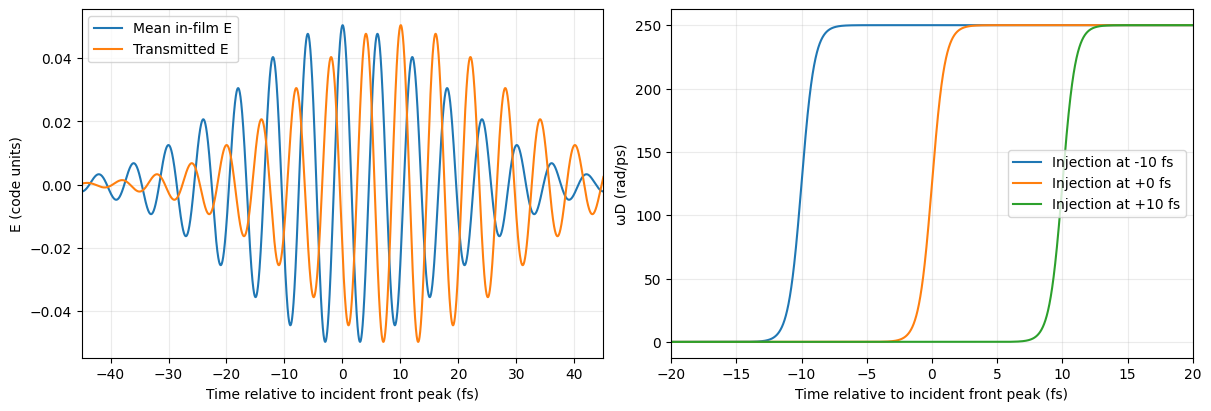

In [3]:
def simulate_trace(gamma, injection_offset_fs=None, record_material=False):
    """Run the probe with a uniform tanh Drude step; None disables injection."""
    if injection_offset_fs is None:
        omega_D = np.zeros(Nt)
    else:
        injection_ps = front_peak_ps+injection_offset_fs*1e-3
        omega_D = OMEGA_D_FINAL*0.5*(1+np.tanh((t_ps-injection_ps)/(STEP_WIDTH_FS*1e-3)))
    material = MaterialParamsTD.from_static(Nt=Nt, omega_D=0, gamma_D=gamma,
                                            omega_L=0, gamma_L=0, del_eps=0, eps_inf=1)
    material = MaterialParamsTD(omega_D=omega_D, gamma_D=material.gamma_D,
                                omega_L=material.omega_L, gamma_L=material.gamma_L,
                                del_eps=material.del_eps, eps_inf=material.eps_inf)
    result = run_simulation(params, pulse, material, method="sio2_background",
                            explicit_pulse_waveform=waveform,
                            material_probe_indices=np.arange(metal_i0, metal_i1) if record_material else None)
    fields = dict(t_ps=t_ps, E_t=result[0], E_r=result[1])
    if record_material:
        fields["E_material_mean"] = result[4]["E"].mean(axis=1)
    if not all(np.all(np.isfinite(x)) for x in fields.values()):
        raise RuntimeError("Nonfinite simulated fields.")
    return fields


def save_trace(path, fields):
    """Save a complete compressed trace atomically, so interrupted writes are not reused."""
    temporary = path.with_suffix(".tmp.npz")
    np.savez_compressed(temporary, **fields)
    temporary.replace(path)


reference_path = OUTPUT_DIR / "unpumped_reference.npz"
if not reference_path.exists():
    save_trace(reference_path, simulate_trace(0.0, record_material=True))
with np.load(reference_path) as saved:
    reference = {key: saved[key] for key in saved.files}
reference_A = -cumulative_trapezoid(reference["E_material_mean"], t_ps, initial=0)
reference_A_transmitted = -cumulative_trapezoid(reference["E_t"], t_ps, initial=0)
np.savez_compressed(OUTPUT_DIR / "reference_vector_potentials.npz", t_ps=t_ps,
                    A_material=reference_A, A_transmitted=reference_A_transmitted)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
x_fs = (t_ps-front_peak_ps)*1e3
axes[0].plot(x_fs, reference["E_material_mean"], label="Mean in-film E")
axes[0].plot(x_fs, reference["E_t"], label="Transmitted E")
axes[0].set(xlim=(-45, 45), xlabel="Time relative to incident front peak (fs)", ylabel="E (code units)")
axes[0].legend(); axes[0].grid(alpha=0.25)
for offset in (-10, 0, 10):
    omega=OMEGA_D_FINAL*0.5*(1+np.tanh((x_fs-offset)/STEP_WIDTH_FS))
    axes[1].plot(x_fs, omega, label=f"Injection at {offset:+g} fs")
axes[1].set(xlim=(-20,20), xlabel="Time relative to incident front peak (fs)", ylabel="ωD (rad/ps)")
axes[1].legend(); axes[1].grid(alpha=0.25)
fig.savefig(OUTPUT_DIR / "reference_and_uniform_steps.png", dpi=180)
plt.show()

In [4]:
# Run and checkpoint the three injection-time scans; no pump is propagated.
for gamma in GAMMAS_PER_PS:
    folder = OUTPUT_DIR / f"gamma_{gamma:g}_per_ps"
    folder.mkdir(exist_ok=True)
    rows = [dict(index=i, injection_offset_fs=float(offset),
                 injection_time_ps=float(front_peak_ps+offset*1e-3),
                 probe_minus_injection_delay_fs=float(-offset), file=f"trace_{i:04d}.npz")
            for i, offset in enumerate(INJECTION_OFFSETS_FS)]
    manifest = dict(complete=False, gamma_per_ps=gamma, runs=rows, completed_indices=[])
    manifest_path = folder / "scan_manifest.json"
    start = time.monotonic()
    try:
        for row in rows:
            path = folder / row["file"]
            if not path.exists():
                save_trace(path, simulate_trace(gamma, row["injection_offset_fs"]))
            manifest["completed_indices"].append(row["index"])
            temporary = manifest_path.with_suffix(".tmp")
            temporary.write_text(json.dumps(manifest, indent=2)); temporary.replace(manifest_path)
            if (row["index"]+1)%10 == 0 or row["index"] == len(rows)-1:
                print(f"γ={gamma:g}: {row['index']+1}/{len(rows)} traces, {time.monotonic()-start:.1f} s", flush=True)
        manifest["complete"] = True
    finally:
        manifest_path.write_text(json.dumps(manifest, indent=2))
print("All no-pump simulations are saved.")

γ=0: 10/151 traces, 44.8 s


γ=0: 20/151 traces, 88.6 s


γ=0: 30/151 traces, 134.7 s


γ=0: 40/151 traces, 179.0 s


γ=0: 50/151 traces, 231.1 s


γ=0: 60/151 traces, 286.7 s


... (39 outputs left out)

γ=200: 140/151 traces, 0.2 s


γ=200: 150/151 traces, 38.4 s


γ=200: 151/151 traces, 42.6 s


All no-pump simulations are saved.


## Single-lobe analysis and exponential fit (saved data only)
The remaining cells can be run independently of the simulation cells. A cubic interpolant through the sampled lobe-energy response supplies its time derivative; no smoothing or absolute-value envelope is imposed. Fit points must be inside `FIT_WINDOW_FS`, before the selected reference lobe begins (mapped back to the film), and satisfy $|A|\geq 0.15\max|A|$. The fit solves the signed amplitude analytically at each rate, searches a coarse rate grid, and refines the lowest-error interval with scalar least squares. The configurable rate search covers ±5000 ps⁻¹; γ = 0 is the constant-envelope case.

A warning is issued for >10% RMS relative fit error, >10% significant sign mismatches, a growing rather than decaying fitted exponential, or a fitted rate differing from the imposed rate by more than max(25 ps⁻¹, 25%). These are transparent model-check thresholds, not statistical confidence claims. The expected fixed-γ curve is also fitted in amplitude and tested. Finite-difference disagreement and transmitted tails are reported separately.

In [2]:
# Analysis-only imports/configuration: run this cell and the following cells after a kernel restart.
from pathlib import Path
import json, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar
from scipy.signal import find_peaks
analysis_package = next((candidate for root in (Path.cwd(), *Path.cwd().parents)
                         for candidate in (root, root / "lightmatter")
                         if (candidate / "src/lightmatter/fdtd_revised_sio2.py").is_file()), None)
if analysis_package is None:
    raise FileNotFoundError("Run inside the lightmatter workspace.")
ANALYSIS_DIR = analysis_package / "output/project2/forward_model_checks/infer_gamma_no_pump_sio2_10nm_probe166THz_30fs_omegaD250_tanh1fs_gamma0_100_200"
FIT_WINDOW_FS = (-30.0, -3.0)
A_MIN_FRACTION = 0.15
MAX_EXPONENTIAL_NRMSE = 0.10
MAX_SIGN_MISMATCH_FRACTION = 0.10
MIN_FIT_POINTS = 20
FIT_RATE_BOUND_PER_PS = 5000.0
TAIL_CHECK_FS = 10.0
TAIL_ENERGY_TOLERANCE = 1e-4


def lobe_energy(time_ps, field, target_ps):
    """Integrate E² around the nearest positive peak, between its own interpolated zeros."""
    peaks, _ = find_peaks(field)
    peaks = peaks[field[peaks] > 0]
    if not peaks.size:
        raise ValueError("No positive field peaks.")
    peak = peaks[np.argmin(abs(time_ps[peaks]-target_ps))]
    crossing = np.flatnonzero(field[:-1]*field[1:] < 0)
    zeros = time_ps[crossing]+(time_ps[crossing+1]-time_ps[crossing])*abs(field[crossing])/(abs(field[crossing])+abs(field[crossing+1]))
    zeros = np.unique(np.r_[zeros, time_ps[field == 0]])
    left, right = zeros[zeros < time_ps[peak]], zeros[zeros > time_ps[peak]]
    if not left.size or not right.size:
        raise ValueError("Selected lobe has no bounding zeros.")
    left, right = float(left[-1]), float(right[0])
    inside = (time_ps > left) & (time_ps < right)
    energy = float(trapezoid(np.r_[0, field[inside], 0]**2, np.r_[left, time_ps[inside], right]))
    if not np.isfinite(energy) or energy <= 0:
        raise ValueError("Nonpositive or nonfinite lobe energy.")
    return dict(energy=energy, peak_ps=float(time_ps[peak]), left_ps=left, right_ps=right)


def fit_exponential(time_ps, values, imposed_gamma):
    """Fit a signed C exp[-rate*(t-t*)]; also test the imposed rate with amplitude free."""
    t_star = float(time_ps[-1])
    x = time_ps-t_star
    scale = float(np.max(abs(values)))
    if scale == 0 or not np.isfinite(scale):
        raise ValueError("Extracted envelope is zero or nonfinite.")
    y = values/scale

    def rate_loss(rate):
        # Profile out amplitude; subtract the largest exponent for numerical stability.
        exponent = -rate*x
        basis = np.exp(exponent-exponent.max())
        coefficient = np.dot(y,basis)/np.dot(basis,basis)
        return float(np.mean((y-coefficient*basis)**2))

    rates = np.linspace(-FIT_RATE_BOUND_PER_PS,FIT_RATE_BOUND_PER_PS,2001)
    best = int(np.argmin([rate_loss(rate) for rate in rates]))
    lower, upper = rates[max(0,best-1)], rates[min(len(rates)-1,best+1)]
    fit = minimize_scalar(rate_loss,bounds=(lower,upper),method="bounded")
    rate = float(min((rates[best],fit.x),key=rate_loss))
    exponent = -rate*x
    basis = np.exp(exponent-exponent.max())
    coefficient = float(np.dot(values,basis)/np.dot(basis,basis))
    amplitude = float(coefficient*np.exp(-exponent.max()))
    prediction = coefficient*basis
    rms = np.sqrt(np.mean(values**2))
    nrmse = float(np.sqrt(np.mean((values-prediction)**2))/rms)
    expected_basis = np.exp(-imposed_gamma*x)
    expected_amplitude = float(np.dot(values,expected_basis)/np.dot(expected_basis,expected_basis))
    expected_prediction = expected_amplitude*expected_basis
    expected_nrmse = float(np.sqrt(np.mean((values-expected_prediction)**2))/rms)
    significant = abs(values) > 0.02*scale
    sign_mismatch = float(np.mean(values[significant]*amplitude < 0))
    messages = []
    if not fit.success or abs(rate) >= 0.999*FIT_RATE_BOUND_PER_PS:
        messages.append("Exponential optimizer failed or reached the rate bound.")
    if nrmse > MAX_EXPONENTIAL_NRMSE:
        messages.append(f"Free exponential has {nrmse:.1%} normalized RMS error.")
    if expected_nrmse > MAX_EXPONENTIAL_NRMSE:
        messages.append(f"Expected input-γ exponential has {expected_nrmse:.1%} normalized RMS error.")
    if sign_mismatch > MAX_SIGN_MISMATCH_FRACTION:
        messages.append(f"{sign_mismatch:.1%} of significant samples have a sign incompatible with one exponential.")
    if rate < -1.0:
        messages.append("Fit grows with injection time (negative fitted γ); injection time and elapsed time since injection have opposite orientation.")
    if abs(rate-imposed_gamma) > max(25.0,0.25*imposed_gamma):
        messages.append("Fitted rate disagrees with the imposed damping beyond the configured tolerance.")
    return dict(gamma_fit_per_ps=rate, imposed_gamma_per_ps=imposed_gamma,
                amplitude=amplitude, expected_amplitude=expected_amplitude, t_star_ps=t_star,
                nrmse=nrmse, expected_nrmse=expected_nrmse, sign_mismatch_fraction=sign_mismatch,
                fit_points=int(time_ps.size), rate_search_bound_per_ps=FIT_RATE_BOUND_PER_PS, warnings=messages, model_consistent=not messages)

In [3]:
config = json.loads((ANALYSIS_DIR / "configuration.json").read_text())
with np.load(ANALYSIS_DIR / "unpumped_reference.npz") as archive:
    ref = {key: archive[key] for key in archive.files}
t = ref["t_ps"]
front_peak = config["front_peak_ps"]
A = -cumulative_trapezoid(ref["E_material_mean"], t, initial=0)
positive_peaks, _ = find_peaks(ref["E_t"])
positive_peaks = positive_peaks[ref["E_t"][positive_peaks] > 0]
target = float(t[positive_peaks[np.argmax(ref["E_t"][positive_peaks])]])
reference_lobe = lobe_energy(t, ref["E_t"], target)
p = config["fdtd_params"]
# Map the transmitted lobe clock back to the middle material cell using the vacuum distance.
# The remaining in-film delay is <0.03 fs for this 10 nm sample.
center_index = (p["metal_i0"]+p["metal_i1"]-1)/2
center_to_detector_ps = (p["probe_t_i"]-center_index)*p["dz"]/2.99792458e6
lobe_start_at_film_ps = reference_lobe["left_ps"]-center_to_detector_ps
analysis_results, fit_summaries = [], []
for gamma in config["gammas_per_ps"]:
    folder = ANALYSIS_DIR / f"gamma_{gamma:g}_per_ps"
    manifest = json.loads((folder / "scan_manifest.json").read_text())
    rows = manifest["runs"]
    if not manifest["complete"] or set(manifest["completed_indices"]) != {row["index"] for row in rows}:
        raise ValueError(f"Incomplete scan: {folder}")
    offsets = np.array([row["injection_offset_fs"] for row in rows])
    injection_times = np.array([row["injection_time_ps"] for row in rows])
    if np.any(np.diff(injection_times) <= 0):
        raise ValueError("Injection times must be increasing for differentiation.")
    energies, peaks, left_zeros, right_zeros, tails = [], [], [], [], []
    for row in rows:
        with np.load(folder / row["file"]) as archive:
            if not np.array_equal(archive["t_ps"], t):
                raise ValueError("Saved time axes differ.")
            field = archive["E_t"]
        lobe = lobe_energy(t, field, target)
        energies.append(lobe["energy"]); peaks.append(lobe["peak_ps"])
        left_zeros.append(lobe["left_ps"]); right_zeros.append(lobe["right_ps"])
        tail = t >= t[-1]-TAIL_CHECK_FS*1e-3
        tails.append(float(trapezoid(field[tail]**2,t[tail])/trapezoid(field**2,t)))
    ratio = np.asarray(energies)/reference_lobe["energy"]
    response = ratio-1
    derivative = CubicSpline(injection_times, response)(injection_times, 1)
    finite_difference = np.gradient(response, injection_times, edge_order=2)
    A_at_injection = np.interp(injection_times, t, A)
    division_mask = abs(A_at_injection) >= A_MIN_FRACTION*np.max(abs(A))
    extracted = np.full(offsets.shape, np.nan)
    extracted[division_mask] = -derivative[division_mask]/A_at_injection[division_mask]
    fit_mask = (division_mask & (offsets >= FIT_WINDOW_FS[0]) & (offsets <= FIT_WINDOW_FS[1])
                & (injection_times < lobe_start_at_film_ps))
    if fit_mask.sum() < MIN_FIT_POINTS:
        raise ValueError(f"Only {fit_mask.sum()} fit points for γ={gamma:g}; inspect A and the fit window.")
    summary = fit_exponential(injection_times[fit_mask], extracted[fit_mask], gamma)
    derivative_disagreement = float(np.linalg.norm((derivative-finite_difference)[fit_mask])/
                                    max(np.linalg.norm(derivative[fit_mask]),np.finfo(float).tiny))
    summary.update(derivative_disagreement_fraction=derivative_disagreement,
                   maximum_tail_energy_fraction=float(max(tails)),
                   maximum_peak_shift_fs=float(np.max(abs(np.asarray(peaks)-target))*1e3),
                   fit_window_fs=list(FIT_WINDOW_FS), A_min_fraction=A_MIN_FRACTION,
                   reference_lobe=reference_lobe)
    if derivative_disagreement > 0.05:
        summary["warnings"].append("Spline and finite-difference derivatives differ by >5%; check injection-time resolution.")
    if max(tails) > TAIL_ENERGY_TOLERANCE:
        summary["warnings"].append(f"Some traces retain transmitted energy in the final {TAIL_CHECK_FS:g} fs; inspect recording-duration convergence.")
    if summary["maximum_peak_shift_fs"] > 1000/(4*config["pulse_params"]["f0"]):
        summary["warnings"].append("Selected peak shifted by more than a quarter cycle; inspect lobe tracking.")
    summary["model_consistent"] = not summary["warnings"]
    for message in summary["warnings"]:
        warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
    result = dict(injection_offset_fs=offsets, injection_time_ps=injection_times,
                  lobe_energy=np.asarray(energies), lobe_ratio=ratio, derivative_per_ps=derivative,
                  finite_difference_per_ps=finite_difference, A_at_injection=A_at_injection,
                  extracted_envelope=extracted, division_mask=division_mask, fit_mask=fit_mask,
                  peak_time_ps=np.asarray(peaks), left_zero_ps=np.asarray(left_zeros),
                  right_zero_ps=np.asarray(right_zeros), tail_energy_fraction=np.asarray(tails))
    np.savez_compressed(folder / "lobe_and_envelope_analysis.npz", **result)
    (folder / "exponential_fit.json").write_text(json.dumps(summary,indent=2))
    analysis_results.append(result); fit_summaries.append(summary)
    print(f"γ input={gamma:g}; fitted={summary['gamma_fit_per_ps']:.4f} ps⁻¹; "
          f"free-fit NRMSE={summary['nrmse']:.2%}; expected-γ NRMSE={summary['expected_nrmse']:.2%}")
(ANALYSIS_DIR / "fit_summary.json").write_text(json.dumps(fit_summaries,indent=2))

/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=0 ps⁻¹: Free exponential has 90.8% normalized RMS error.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=0 ps⁻¹: Expected input-γ exponential has 94.2% normalized RMS error.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=0 ps⁻¹: 30.8% of significant samples have a sign incompatible with one exponential.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=0 ps⁻¹: Fit grows with injection time (negative fitted γ); injection time and elapsed time since injection have opposite orientation.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=0 ps⁻¹: Fitted rate disagrees with the imposed damping beyond the configured tolerance.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")


γ input=0; fitted=-2226.6822 ps⁻¹; free-fit NRMSE=90.80%; expected-γ NRMSE=94.18%


/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=100 ps⁻¹: Free exponential has 70.5% normalized RMS error.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=100 ps⁻¹: Expected input-γ exponential has 99.4% normalized RMS error.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=100 ps⁻¹: 26.2% of significant samples have a sign incompatible with one exponential.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=100 ps⁻¹: Fit grows with injection time (negative fitted γ); injection time and elapsed time since injection have opposite orientation.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=100 ps⁻¹: Fitted rate disagrees with the imposed damping beyond the configured tolerance.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")


γ input=100; fitted=-2242.6996 ps⁻¹; free-fit NRMSE=70.53%; expected-γ NRMSE=99.37%


γ input=200; fitted=-2266.0204 ps⁻¹; free-fit NRMSE=49.53%; expected-γ NRMSE=99.99%


/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=200 ps⁻¹: Free exponential has 49.5% normalized RMS error.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=200 ps⁻¹: Expected input-γ exponential has 100.0% normalized RMS error.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=200 ps⁻¹: 24.0% of significant samples have a sign incompatible with one exponential.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=200 ps⁻¹: Fit grows with injection time (negative fitted γ); injection time and elapsed time since injection have opposite orientation.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_76671/3577629626.py:67: UserWarning: γ=200 ps⁻¹: Fitted rate disagrees with the imposed damping beyond the configured tolerance.
  warnings.warn(f"γ={gamma:g} ps⁻¹: {message}")


3944

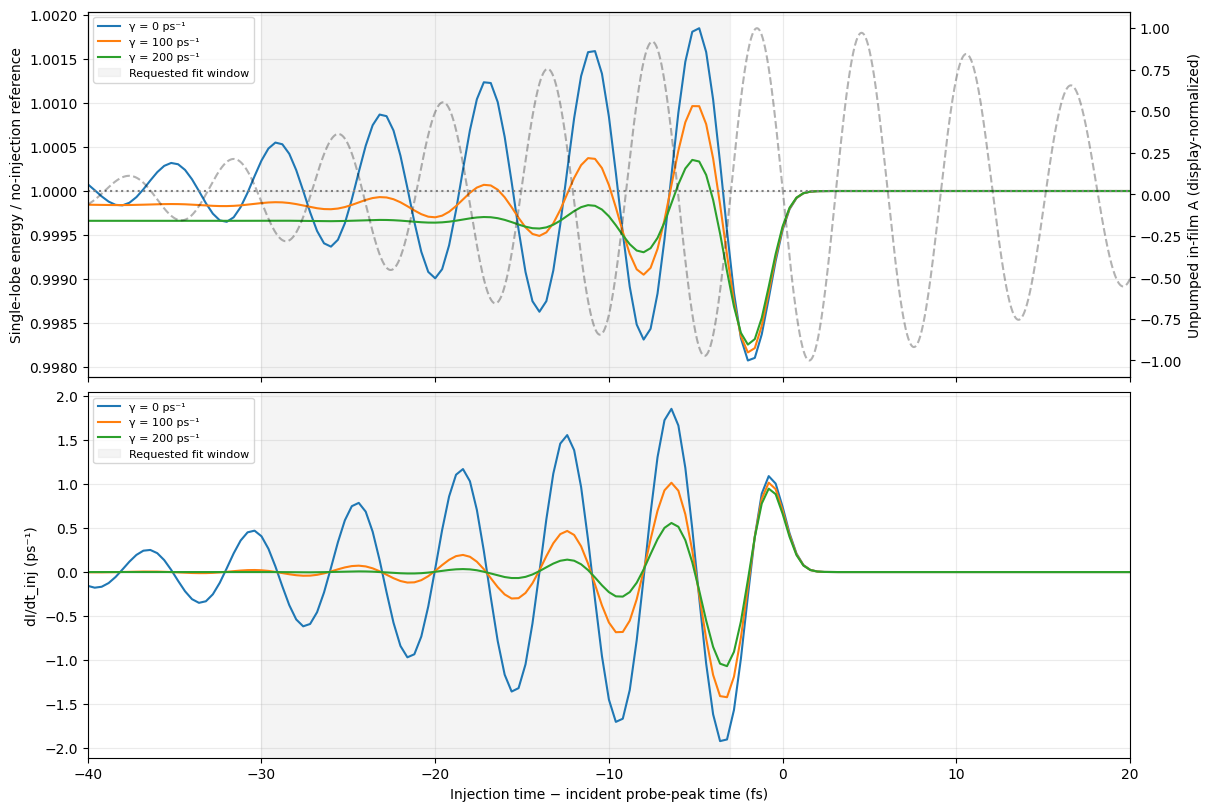

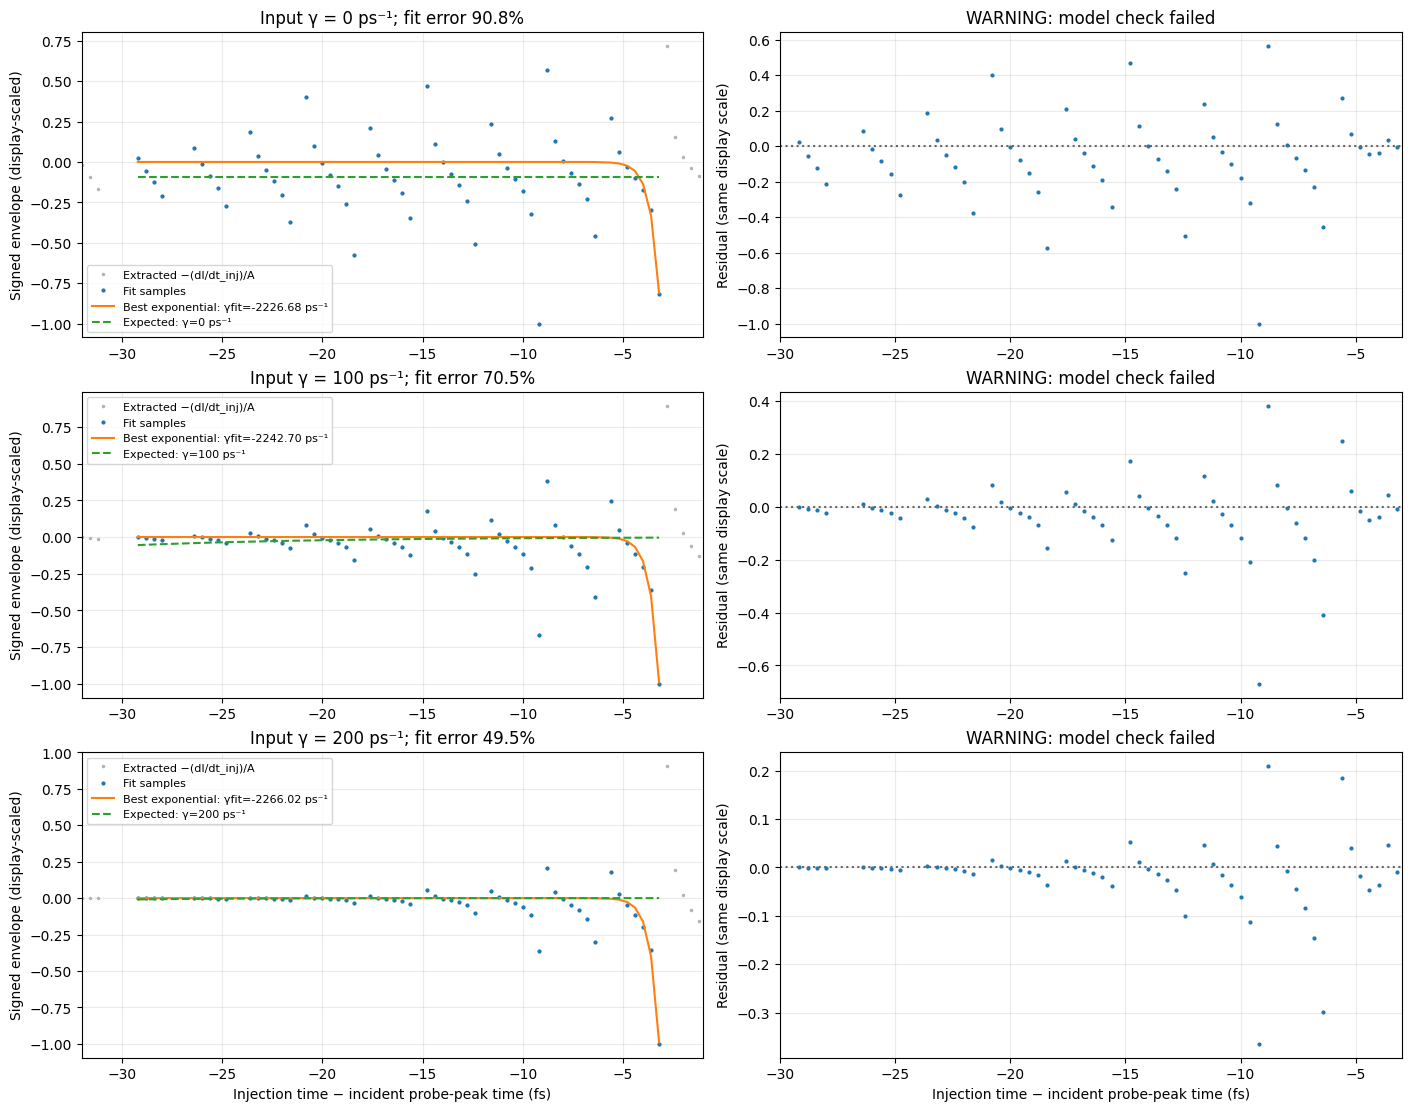

Results and fit diagnostics: /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/infer_gamma_no_pump_sio2_10nm_probe166THz_30fs_omegaD250_tanh1fs_gamma0_100_200


In [4]:
# Plot the measured lobe response and its differentiated response, with the reference A.
fig, axes = plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
for result, summary in zip(analysis_results,fit_summaries):
    gamma = summary["imposed_gamma_per_ps"]
    axes[0].plot(result["injection_offset_fs"],result["lobe_ratio"],label=f"γ = {gamma:g} ps⁻¹")
    axes[1].plot(result["injection_offset_fs"],result["derivative_per_ps"],label=f"γ = {gamma:g} ps⁻¹")
axes[0].axhline(1,color="0.5",ls=":")
axes[0].set(ylabel="Single-lobe energy / no-injection reference")
axes[1].set(xlabel="Injection time − incident probe-peak time (fs)",ylabel="dI/dt_inj (ps⁻¹)")
for ax in axes:
    ax.axvspan(*FIT_WINDOW_FS,color="0.8",alpha=0.2,label="Requested fit window")
    ax.grid(alpha=0.25);ax.legend(loc="upper left",fontsize=8)
reference_axis=axes[0].twinx()
reference_axis.plot((t-front_peak)*1e3,A/np.max(abs(A)),color="black",ls="--",alpha=0.3)
reference_axis.set_ylabel("Unpumped in-film A (display-normalized)")
axes[0].set_xlim(config["injection_offsets_fs"][0],config["injection_offsets_fs"][-1])
for ext in ("png","pdf"):fig.savefig(ANALYSIS_DIR/f"single_lobe_and_derivative.{ext}",dpi=180)
plt.show()

# Keep the signed extracted envelope: an absolute value could hide failure of the model.
fig, axes = plt.subplots(3,2,figsize=(14,11),constrained_layout=True)
for row,(result,summary) in enumerate(zip(analysis_results,fit_summaries)):
    mask=result["fit_mask"]; x=result["injection_offset_fs"]
    times=result["injection_time_ps"]
    amplitude=summary["amplitude"]
    display_scale=float(np.max(abs(result["extracted_envelope"][mask])))
    fit_curve=amplitude*np.exp(-summary["gamma_fit_per_ps"]*(times-summary["t_star_ps"]))
    expected_curve=summary["expected_amplitude"]*np.exp(-summary["imposed_gamma_per_ps"]*(times-summary["t_star_ps"]))
    ax=axes[row,0]
    visible=(x >= FIT_WINDOW_FS[0]-2) & (x <= FIT_WINDOW_FS[1]+2)
    ax.plot(x[visible],result["extracted_envelope"][visible]/display_scale,".",ms=3,color="0.7",label="Extracted −(dI/dt_inj)/A")
    ax.plot(x[mask],result["extracted_envelope"][mask]/display_scale,".",ms=4,label="Fit samples")
    ax.plot(x[mask],fit_curve[mask]/display_scale,label=f"Best exponential: γfit={summary['gamma_fit_per_ps']:.2f} ps⁻¹")
    ax.plot(x[mask],expected_curve[mask]/display_scale,"--",label=f"Expected: γ={summary['imposed_gamma_per_ps']:g} ps⁻¹")
    ax.set(xlim=(FIT_WINDOW_FS[0]-2,FIT_WINDOW_FS[1]+2),ylabel="Signed envelope (display-scaled)",
           title=f"Input γ = {summary['imposed_gamma_per_ps']:g} ps⁻¹; fit error {summary['nrmse']:.1%}")
    ax.legend(fontsize=8);ax.grid(alpha=0.25)
    residual=(result["extracted_envelope"]-fit_curve)/display_scale
    axes[row,1].plot(x[mask],residual[mask],".",ms=4)
    axes[row,1].axhline(0,color="0.4",ls=":")
    axes[row,1].set(xlim=FIT_WINDOW_FS,ylabel="Residual (same display scale)",
                    title="WARNING: model check failed" if summary["warnings"] else "Exponential model passes configured checks")
    axes[row,1].grid(alpha=0.25)
for ax in axes[-1]: ax.set_xlabel("Injection time − incident probe-peak time (fs)")
for ext in ("png","pdf"):fig.savefig(ANALYSIS_DIR/f"extracted_envelopes_and_exponential_fits.{ext}",dpi=180)
plt.show()
print("Results and fit diagnostics:",ANALYSIS_DIR)

## Modified lobe analysis

We modify the predicted form of the envelope to be:

$$ g(t) = \frac{I(t)}{\int^{t}_{t_{inj}}A(t)dt} $$

In this modified analysis, we change the definition of the lobe limits over which the integrated energy is calculated. Firstly, the associated $A(t)$ for the given $E(t)$ is calculated. We then find choose a lobe, i.e. the interval between two successive zero crossings in the vector field, say [$t_0$, $t_1$], and evaluate the energy of the lobe as $\int_{t_0}^{t_1}E^2(t)dt$. This would approximately be two half-lobes compared to the previous analysis. 

To avoid the divergences, we only divide the values at identified peaks and valleys of the integral $I$ and the integral of the vector potential $A$, identifying closest peaks and valleys respectively. This yields far less points, but will probably be more meaningful.

### Modified analysis on saved traces

Run the following cells together after a kernel restart; they only read saved fields. New outputs go in `modified_vector_potential_lobes/` and the earlier analysis is preserved.

For each transmitted trace, calculate $A_{\rm tr}(t)=-\int E_{\rm tr}(t)\,dt$, with A zero at the beginning of the record. Select the same-polarity A lobe nearest the strongest unpumped A extremum. Integrate **raw** $I=\int_{t_0}^{t_1}E_{\rm tr}^2\,dt$ between that trace's own consecutive A zero crossings, including the interpolated, generally nonzero E values at both boundaries. No background subtraction or differentiation is applied.

The notation in the preceding cell is implemented as an injection-time scan: the denominator is $B(t_{\rm inj})=\int_{t_{\rm inj}}^{t_{\rm end}}A_{\rm ref}(s)\,ds$, using the unpumped mean in-film A and the **fixed unpumped lobe end**, back-propagated from the detector to the film. The residual in-film timing correction is below 0.03 fs for this sample. Thus the chosen upper observation time is held fixed while the injection time changes.

Find maxima and minima of I and B separately versus injection time. Pair each I maximum with its nearest B maximum, and likewise minima, without reusing a denominator extremum; refine extrema quadratically over three samples. Reject pairs separated by more than half a carrier period or with $|B|<0.05\max|B|$ over the scan. These thresholds are adjustable below. Form $g_j=I(t_{I,j})/B(t_{B,j})$ **only at matched extrema**, and associate each ratio with its numerator time $t_{I,j}$; both times and their mismatch are saved.

Fit a signed $C\exp[-\gamma_{\rm fit}(t_I-t_*)]$ to the pooled maxima/minima ratios in the same −30 to −3 fs window as before, requiring both matched times in the window and before the lobe starts at the film. Mark the two kinds of extrema separately in the plots. A free amplitude also fits the expected input-γ exponential. Warnings use the previous 10% normalized RMS-error threshold, sign consistency, rate disagreement, and growth/bound checks. Fewer than four valid points produces a warning instead of an unsupported fit. Negative rates describe growth with injection time, whose orientation is opposite to elapsed time after injection. This remains a test of the proposed formula, with no absolute-value envelope imposed.

In [2]:
# Standalone modified-analysis setup: no solver imports or simulation calls.
from pathlib import Path
import json, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid, trapezoid
from scipy.signal import find_peaks
from scipy.optimize import minimize_scalar

modified_package = next((candidate for root in (Path.cwd(), *Path.cwd().parents)
                         for candidate in (root, root / "lightmatter")
                         if (candidate / "src/lightmatter/fdtd_revised_sio2.py").is_file()), None)
if modified_package is None:
    raise FileNotFoundError("Run inside the lightmatter workspace.")
MODIFIED_DATA_DIR = modified_package / "output/project2/forward_model_checks/infer_gamma_no_pump_sio2_10nm_probe166THz_30fs_omegaD250_tanh1fs_gamma0_100_200"
MODIFIED_OUTPUT_DIR = MODIFIED_DATA_DIR / "modified_vector_potential_lobes"
MODIFIED_OUTPUT_DIR.mkdir(exist_ok=True)
MODIFIED_FIT_WINDOW_FS = (-30.0, -3.0)
EXTREMUM_PROMINENCE_FRACTION = 0.005
DENOMINATOR_MIN_FRACTION = 0.05
MODIFIED_MIN_FIT_POINTS = 4
MODIFIED_MAX_NRMSE = 0.10
MODIFIED_RATE_BOUND = 5000.0  # ps^-1, signed rate search as in the earlier fit


def vector_potential_lobe(time_ps, field, target_ps, polarity):
    """Integrate E² between the A zero crossings enclosing the selected A extremum."""
    potential = -cumulative_trapezoid(field,time_ps,initial=0)
    peaks, _ = find_peaks(polarity*potential)
    peaks = peaks[polarity*potential[peaks] > 0]
    if not peaks.size:
        raise ValueError("No vector-potential extremum of the reference polarity.")
    peak = peaks[np.argmin(abs(time_ps[peaks]-target_ps))]
    crossing = np.flatnonzero(potential[:-1]*potential[1:] < 0)
    zeros = time_ps[crossing]-potential[crossing]*np.diff(time_ps)[crossing]/np.diff(potential)[crossing]
    zeros = np.unique(np.r_[zeros,time_ps[potential == 0]])
    left, right = zeros[zeros < time_ps[peak]], zeros[zeros > time_ps[peak]]
    if not left.size or not right.size:
        raise ValueError("Selected A lobe has no bounding zeros.")
    left, right = float(left[-1]), float(right[0])
    inside = (time_ps > left) & (time_ps < right)
    grid = np.r_[left,time_ps[inside],right]
    energy = float(trapezoid(np.interp(grid,time_ps,field)**2,grid))
    return dict(energy=energy,left_ps=left,right_ps=right,peak_ps=float(time_ps[peak]))


def refined_extrema(x, y, sign):
    """Find prominent maxima (+1) or minima (-1), then refine locally with a parabola."""
    indices, _ = find_peaks(sign*y,prominence=EXTREMUM_PROMINENCE_FRACTION*np.ptp(y))
    points = []
    for i in indices:
        a,b,c = np.polyfit(x[i-1:i+2]-x[i],y[i-1:i+2],2)
        shift = -b/(2*a) if a != 0 else 0.0
        if not x[i-1]-x[i] <= shift <= x[i+1]-x[i]:
            shift = 0.0
        points.append((float(x[i]+shift),float(a*shift**2+b*shift+c)))
    return np.asarray(points,dtype=float).reshape(-1,2)


def pair_extrema(x, energy, denominator, max_separation_fs):
    """Match same-kind extrema by nearest time; prevent reuse and reject small denominators."""
    pairs, rejected = [], []
    threshold = DENOMINATOR_MIN_FRACTION*np.max(abs(denominator))
    for kind,sign in (("maximum",1),("minimum",-1)):
        numerator = refined_extrema(x,energy,sign)
        divisor = refined_extrema(x,denominator,sign)
        used = set()
        # Closest pairs get first choice; never replace a rejected match with a distant one.
        candidates = [(abs(a[0]-divisor[j,0]),i,j)
                      for i,a in enumerate(numerator)
                      for j in ([int(np.argmin(abs(divisor[:,0]-a[0])))] if len(divisor) else [])]
        for separation,i,j in sorted(candidates):
            tx,value = numerator[i]; tb,bvalue = divisor[j]
            reason = ("reused denominator extremum" if j in used else
                      "extrema too far apart" if separation > max_separation_fs else
                      "denominator too small" if abs(bvalue) <= threshold else None)
            row = dict(kind=kind,numerator_offset_fs=float(tx),denominator_offset_fs=float(tb),
                       separation_fs=float(separation),energy=float(value),denominator=float(bvalue))
            if reason:
                rejected.append(dict(row,reason=reason))
            else:
                used.add(j)
                pairs.append(dict(row,envelope=float(value/bvalue)))
    return sorted(pairs,key=lambda row:row["numerator_offset_fs"]),rejected


def fit_modified_exponential(time_ps, values, imposed_gamma):
    """Least-squares exponential fit with analytic signed amplitude and a one-dimensional rate search."""
    origin = float(time_ps[-1]); x = time_ps-origin
    scale = float(np.max(abs(values))); y = values/scale
    def solve_rate(rate):
        exponent = -rate*x
        basis = np.exp(exponent-exponent.max())
        coefficient = np.dot(y,basis)/np.dot(basis,basis)
        return float(np.mean((y-coefficient*basis)**2)),float(coefficient*scale*np.exp(-exponent.max()))
    rates = np.linspace(-MODIFIED_RATE_BOUND,MODIFIED_RATE_BOUND,2001)
    index = int(np.argmin([solve_rate(rate)[0] for rate in rates]))
    optimum = minimize_scalar(lambda rate:solve_rate(rate)[0],method="bounded",
                              bounds=(rates[max(0,index-1)],rates[min(len(rates)-1,index+1)]))
    rate = float(min((rates[index],optimum.x),key=lambda rate:solve_rate(rate)[0]))
    error,amplitude = solve_rate(rate)
    expected_error,expected_amplitude = solve_rate(imposed_gamma)
    nrmse = float(np.sqrt(error/np.mean(y**2)))
    expected_nrmse = float(np.sqrt(expected_error/np.mean(y**2)))
    significant = abs(values) > 0.02*scale
    sign_mismatch = float(np.mean(values[significant]*amplitude < 0))
    messages = []
    if not optimum.success or abs(rate) >= 0.999*MODIFIED_RATE_BOUND:
        messages.append("Exponential optimizer failed or reached the rate bound.")
    if nrmse > MODIFIED_MAX_NRMSE:
        messages.append(f"Free exponential has {nrmse:.1%} normalized RMS error.")
    if expected_nrmse > MODIFIED_MAX_NRMSE:
        messages.append(f"Expected input-γ exponential has {expected_nrmse:.1%} normalized RMS error.")
    if sign_mismatch > 0.10:
        messages.append(f"{sign_mismatch:.1%} of significant ratios have an incompatible sign.")
    if rate < -1.0:
        messages.append("Fit grows with injection time (negative rate); this coordinate is opposite to elapsed time since injection.")
    if abs(rate-imposed_gamma) > max(25.0,0.25*imposed_gamma):
        messages.append("Fitted rate disagrees with the imposed damping beyond the configured tolerance.")
    return dict(imposed_gamma_per_ps=float(imposed_gamma),gamma_fit_per_ps=rate,
                amplitude=amplitude,expected_amplitude=expected_amplitude,t_star_ps=origin,
                nrmse=nrmse,expected_nrmse=expected_nrmse,sign_mismatch_fraction=sign_mismatch,
                fit_points=int(values.size),warnings=messages,model_consistent=not messages)


In [3]:
# Read the original stored traces, recompute A-defined lobe energies, and fit matched extrema.
modified_config = json.loads((MODIFIED_DATA_DIR / "configuration.json").read_text())
with np.load(MODIFIED_DATA_DIR / "unpumped_reference.npz") as archive:
    modified_ref = {key:archive[key] for key in archive.files}
modified_t = modified_ref["t_ps"]
modified_front = modified_config["front_peak_ps"]
modified_A_transmitted = -cumulative_trapezoid(modified_ref["E_t"],modified_t,initial=0)
modified_A_material = -cumulative_trapezoid(modified_ref["E_material_mean"],modified_t,initial=0)
modified_peak_index = int(np.argmax(abs(modified_A_transmitted)))
modified_target = float(modified_t[modified_peak_index])
modified_polarity = float(np.sign(modified_A_transmitted[modified_peak_index]))
modified_ref_lobe = vector_potential_lobe(modified_t,modified_ref["E_t"],modified_target,modified_polarity)
geometry = modified_config["fdtd_params"]
modified_flight_ps = (geometry["probe_t_i"]-(geometry["metal_i0"]+geometry["metal_i1"]-1)/2)*geometry["dz"]/2.99792458e6
modified_upper_ps = modified_ref_lobe["right_ps"]-modified_flight_ps
modified_lower_ps = modified_ref_lobe["left_ps"]-modified_flight_ps
modified_primitive = cumulative_trapezoid(modified_A_material,modified_t,initial=0)
modified_half_period_fs = 500/modified_config["pulse_params"]["f0"]
modified_results, modified_summaries = [], []
for gamma in modified_config["gammas_per_ps"]:
    folder = MODIFIED_DATA_DIR / f"gamma_{gamma:g}_per_ps"
    manifest = json.loads((folder / "scan_manifest.json").read_text())
    if not manifest["complete"] or set(manifest["completed_indices"]) != {row["index"] for row in manifest["runs"]}:
        raise ValueError(f"Incomplete stored scan: {folder}")
    rows = sorted(manifest["runs"],key=lambda row:row["injection_time_ps"])
    offsets = np.array([row["injection_offset_fs"] for row in rows])
    injection_times = np.array([row["injection_time_ps"] for row in rows])
    if not np.all(np.diff(injection_times) > 0):
        raise ValueError("Injection times must be strictly increasing.")
    lobes = []
    for row in rows:
        with np.load(folder / row["file"]) as archive:
            if not np.array_equal(archive["t_ps"],modified_t) or not np.all(np.isfinite(archive["E_t"])):
                raise ValueError("Invalid stored field or inconsistent time axis.")
            lobes.append(vector_potential_lobe(modified_t,archive["E_t"],modified_target,modified_polarity))
    energy = np.array([lobe["energy"] for lobe in lobes])
    denominator = np.interp(modified_upper_ps,modified_t,modified_primitive)-np.interp(injection_times,modified_t,modified_primitive)
    pairs,rejected = pair_extrema(offsets,energy,denominator,modified_half_period_fs)
    for pair in pairs:
        a,b = pair["numerator_offset_fs"],pair["denominator_offset_fs"]
        pair["used_in_fit"] = bool(MODIFIED_FIT_WINDOW_FS[0] <= a <= MODIFIED_FIT_WINDOW_FS[1]
                                  and MODIFIED_FIT_WINDOW_FS[0] <= b <= MODIFIED_FIT_WINDOW_FS[1]
                                  and modified_front+max(a,b)*1e-3 < modified_lower_ps)
    fit_pairs = [pair for pair in pairs if pair["used_in_fit"]]
    fit_times = modified_front+1e-3*np.array([pair["numerator_offset_fs"] for pair in fit_pairs])
    fit_values = np.array([pair["envelope"] for pair in fit_pairs])
    if len(fit_pairs) >= MODIFIED_MIN_FIT_POINTS:
        summary = fit_modified_exponential(fit_times,fit_values,gamma)
    else:
        summary = dict(imposed_gamma_per_ps=float(gamma),gamma_fit_per_ps=None,fit_points=len(fit_pairs),
                       warnings=[f"Only {len(fit_pairs)} valid matched extrema; need {MODIFIED_MIN_FIT_POINTS} for an exponential fit."],model_consistent=False)
    max_shift = float(max(abs(lobe["peak_ps"]-modified_target) for lobe in lobes)*1e3)
    if max_shift > modified_half_period_fs/2:
        summary["warnings"].append("A-lobe extremum shifted by more than a quarter cycle; inspect lobe tracking.")
    summary.update(reference_lobe=modified_ref_lobe,upper_limit_at_film_ps=modified_upper_ps,
                   denominator_source="unpumped mean in-film vector potential",numerator="raw A-bounded transmitted lobe energy",
                   fit_window_fs=list(MODIFIED_FIT_WINDOW_FS),maximum_lobe_peak_shift_fs=max_shift,
                   denominator_min_fraction=DENOMINATOR_MIN_FRACTION,prominence_fraction=EXTREMUM_PROMINENCE_FRACTION,
                   maximum_pair_separation_fs=modified_half_period_fs,rate_search_bound_per_ps=MODIFIED_RATE_BOUND,
                   nrmse_warning_threshold=MODIFIED_MAX_NRMSE,pairs=pairs,rejected_pairs=rejected)
    summary["model_consistent"] = not summary["warnings"]
    for message in summary["warnings"]:
        warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")
    result = dict(injection_offset_fs=offsets,injection_time_ps=injection_times,lobe_energy=energy,
                  denominator=denominator,lobe_left_ps=np.array([lobe["left_ps"] for lobe in lobes]),
                  lobe_right_ps=np.array([lobe["right_ps"] for lobe in lobes]),
                  lobe_peak_ps=np.array([lobe["peak_ps"] for lobe in lobes]))
    np.savez_compressed(MODIFIED_OUTPUT_DIR/f"gamma_{gamma:g}_analysis.npz",**result)
    (MODIFIED_OUTPUT_DIR/f"gamma_{gamma:g}_fit.json").write_text(json.dumps(summary,indent=2))
    modified_results.append(result); modified_summaries.append(summary)
    if summary["gamma_fit_per_ps"] is not None:
        print(f"γ={gamma:g}: {len(fit_pairs)} matched fit points; γfit={summary['gamma_fit_per_ps']:.3f} ps⁻¹; "
              f"NRMSE={summary['nrmse']:.1%}; expected-γ NRMSE={summary['expected_nrmse']:.1%}")
(MODIFIED_OUTPUT_DIR/"fit_summary.json").write_text(json.dumps(modified_summaries,indent=2))


/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=0 ps⁻¹: Free exponential has 72.9% normalized RMS error.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=0 ps⁻¹: Expected input-γ exponential has 76.9% normalized RMS error.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=0 ps⁻¹: Fit grows with injection time (negative rate); this coordinate is opposite to elapsed time since injection.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=0 ps⁻¹: Fitted rate disagrees with the imposed damping beyond the configured tolerance.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")


γ=0: 8 matched fit points; γfit=-51.150 ps⁻¹; NRMSE=72.9%; expected-γ NRMSE=76.9%


/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=100 ps⁻¹: Free exponential has 72.8% normalized RMS error.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=100 ps⁻¹: Expected input-γ exponential has 91.7% normalized RMS error.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=100 ps⁻¹: Fit grows with injection time (negative rate); this coordinate is opposite to elapsed time since injection.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=100 ps⁻¹: Fitted rate disagrees with the imposed damping beyond the configured tolerance.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")


γ=100: 8 matched fit points; γfit=-51.187 ps⁻¹; NRMSE=72.8%; expected-γ NRMSE=91.7%


γ=200: 8 matched fit points; γfit=-51.206 ps⁻¹; NRMSE=72.8%; expected-γ NRMSE=96.6%


/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=200 ps⁻¹: Free exponential has 72.8% normalized RMS error.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=200 ps⁻¹: Expected input-γ exponential has 96.6% normalized RMS error.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=200 ps⁻¹: Fit grows with injection time (negative rate); this coordinate is opposite to elapsed time since injection.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")
/tmp/ipykernel_133114/1758297455.py:63: UserWarning: Modified analysis, γ=200 ps⁻¹: Fitted rate disagrees with the imposed damping beyond the configured tolerance.
  warnings.warn(f"Modified analysis, γ={gamma:g} ps⁻¹: {message}")


17917

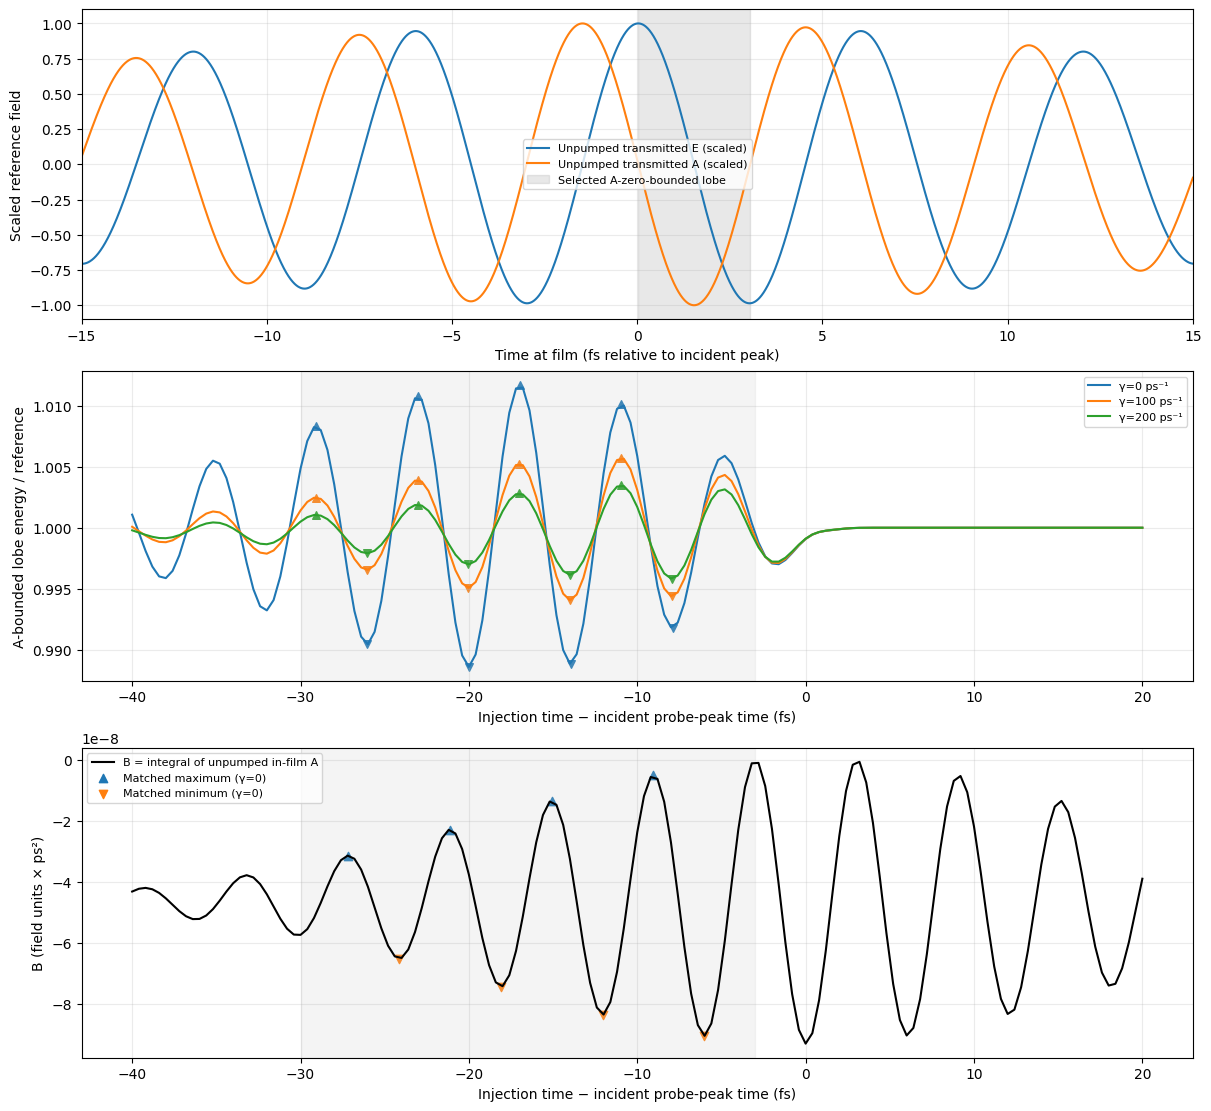

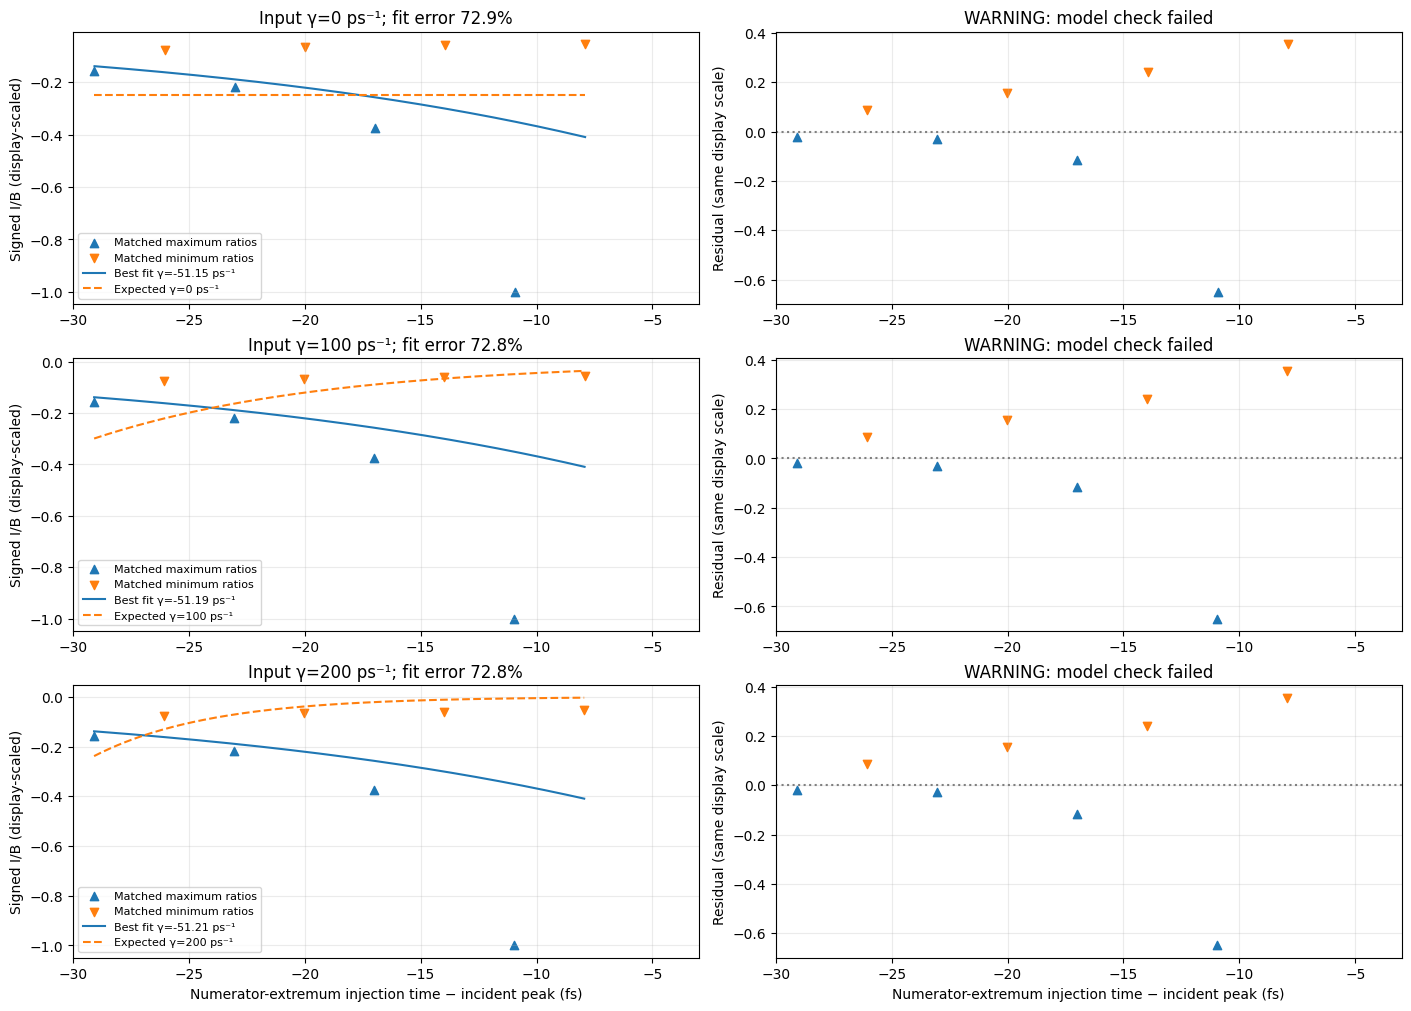

Modified analysis saved to: /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/infer_gamma_no_pump_sio2_10nm_probe166THz_30fs_omegaD250_tanh1fs_gamma0_100_200/modified_vector_potential_lobes


In [4]:
# Show the A-defined reference lobe and the extrema used in the numerator/denominator ratios.
fig,axes = plt.subplots(3,1,figsize=(12,11),constrained_layout=True)
xref = (modified_t-modified_front-modified_flight_ps)*1e3
axes[0].plot(xref,modified_ref["E_t"]/np.max(abs(modified_ref["E_t"])),label="Unpumped transmitted E (scaled)")
axes[0].plot(xref,modified_A_transmitted/np.max(abs(modified_A_transmitted)),label="Unpumped transmitted A (scaled)")
axes[0].axvspan((modified_ref_lobe["left_ps"]-modified_front-modified_flight_ps)*1e3,
               (modified_ref_lobe["right_ps"]-modified_front-modified_flight_ps)*1e3,color="0.7",alpha=0.3,label="Selected A-zero-bounded lobe")
axes[0].set(xlim=(-15,15),ylabel="Scaled reference field",xlabel="Time at film (fs relative to incident peak)")
for result,summary in zip(modified_results,modified_summaries):
    color=axes[1].plot(result["injection_offset_fs"],result["lobe_energy"]/modified_ref_lobe["energy"],
                       label=f"γ={summary['imposed_gamma_per_ps']:g} ps⁻¹")[0].get_color()
    for kind,marker in (("maximum","^"),("minimum","v")):
        selected=[pair for pair in summary["pairs"] if pair["used_in_fit"] and pair["kind"]==kind]
        axes[1].scatter([pair["numerator_offset_fs"] for pair in selected],
                        [pair["energy"]/modified_ref_lobe["energy"] for pair in selected],marker=marker,color=color,s=30)
axes[1].set(ylabel="A-bounded lobe energy / reference")
axes[2].plot(modified_results[0]["injection_offset_fs"],modified_results[0]["denominator"],color="black",label="B = integral of unpumped in-film A")
for kind,marker in (("maximum","^"),("minimum","v")):
    selected=[pair for pair in modified_summaries[0]["pairs"] if pair["used_in_fit"] and pair["kind"]==kind]
    axes[2].scatter([pair["denominator_offset_fs"] for pair in selected],[pair["denominator"] for pair in selected],marker=marker,label=f"Matched {kind} (γ=0)")
axes[2].set(ylabel="B (field units × ps²)")
for ax in axes[1:]:
    ax.axvspan(*MODIFIED_FIT_WINDOW_FS,color="0.8",alpha=0.2)
    ax.set(xlabel="Injection time − incident probe-peak time (fs)")
for ax in axes:
    ax.grid(alpha=0.25); ax.legend(fontsize=8)
for ext in ("png","pdf"):
    fig.savefig(MODIFIED_OUTPUT_DIR/f"vector_potential_lobes_and_matched_extrema.{ext}",dpi=180)
plt.show()

# Plot only the sparse ratios; no pointwise division or interpolation across denominator zeros.
fig,axes = plt.subplots(len(modified_summaries),2,figsize=(14,10),squeeze=False,constrained_layout=True)
for row,summary in enumerate(modified_summaries):
    ax,residual_ax=axes[row]
    selected=[pair for pair in summary["pairs"] if pair["used_in_fit"]]
    x=np.array([pair["numerator_offset_fs"] for pair in selected])
    values=np.array([pair["envelope"] for pair in selected])
    scale=float(np.max(abs(values))) if len(values) else 1.0
    for kind,marker in (("maximum","^"),("minimum","v")):
        keep=np.array([pair["kind"]==kind for pair in selected],dtype=bool)
        ax.scatter(x[keep],values[keep]/scale,marker=marker,label=f"Matched {kind} ratios")
    if summary["gamma_fit_per_ps"] is not None:
        dense=np.linspace(x.min(),x.max(),400)
        relative=modified_front+dense*1e-3-summary["t_star_ps"]
        curve=summary["amplitude"]*np.exp(-summary["gamma_fit_per_ps"]*relative)
        expected=summary["expected_amplitude"]*np.exp(-summary["imposed_gamma_per_ps"]*relative)
        ax.plot(dense,curve/scale,label=f"Best fit γ={summary['gamma_fit_per_ps']:.2f} ps⁻¹")
        ax.plot(dense,expected/scale,"--",label=f"Expected γ={summary['imposed_gamma_per_ps']:g} ps⁻¹")
        predicted=summary["amplitude"]*np.exp(-summary["gamma_fit_per_ps"]*(modified_front+x*1e-3-summary["t_star_ps"]))
        for kind,marker in (("maximum","^"),("minimum","v")):
            keep=np.array([pair["kind"]==kind for pair in selected],dtype=bool)
            residual_ax.scatter(x[keep],(values[keep]-predicted[keep])/scale,marker=marker)
        status=f"fit error {summary['nrmse']:.1%}"
    else:
        status="insufficient matched extrema"
    ax.set(title=f"Input γ={summary['imposed_gamma_per_ps']:g} ps⁻¹; {status}",ylabel="Signed I/B (display-scaled)")
    residual_ax.axhline(0,color="0.5",ls=":")
    residual_ax.set(title="WARNING: model check failed" if summary["warnings"] else "Exponential checks passed",ylabel="Residual (same display scale)")
    ax.legend(fontsize=8)
    for panel in (ax,residual_ax):
        panel.grid(alpha=0.25); panel.set_xlim(MODIFIED_FIT_WINDOW_FS)
for ax in axes[-1]:
    ax.set_xlabel("Numerator-extremum injection time − incident peak (fs)")
for ext in ("png","pdf"):
    fig.savefig(MODIFIED_OUTPUT_DIR/f"modified_envelopes_and_exponential_fits.{ext}",dpi=180)
plt.show()
print("Modified analysis saved to:",MODIFIED_OUTPUT_DIR)
